In [ ]:
!pip install openai-whisper

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 18.9 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for openai-whisper: filename=openai_whisper-20250625-py3-none-any.whl size=803980 sha256=04bdf44a3982cc4eca15ba082cdc63974a1397c87f7dff9662d733fcf78442f1
  Stored in directory: /root/.cache/pip/wheels/61/d2/20/09ec9bef734d126cba375b15898010b6cc28578d8afdde5869
Successfully built openai-whisper


# **Asegurar codec actualizados**

In [ ]:
# 2. Instalar ffmpeg (si no está preinstalado)
!apt update && apt install -y ffmpeg

# 3. Verificar ffmpeg
!ffmpeg -version

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Get:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease [1,581 B]
Hit:4 http://archive.ubuntu.com/ubuntu jammy InRelease
Get:5 http://archive.ubuntu.com/ubuntu jammy-updates InRelease [128 kB]
Get:6 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:7 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Get:8 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]
Get:9 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ Packages [85.2 kB]
Get:10 http://archive.ubuntu.com/ubuntu jammy-backports InRelease [127 kB]
Get:11 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  Packages [2,388 kB]
Get:12 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease [18.1 kB]
Hit:13 https://ppa.launchpadcontent.net/graphics-driver

# **Funcion para generar transcripción**

In [ ]:
import whisper

def transcribe_audio(file_path, model_type="small", idioma = "es"): #argumentos: ruta archivo, variante del modelo whisper, tipo de idioma en audio español (es), ingles (en)

    """Transcribe audio files using Whisper."""

    # Cargar Whisper model
    model = whisper.load_model(model_type)

    # Ejecutar transcription
    result = model.transcribe(file_path,language=idioma)
    return result["text"]

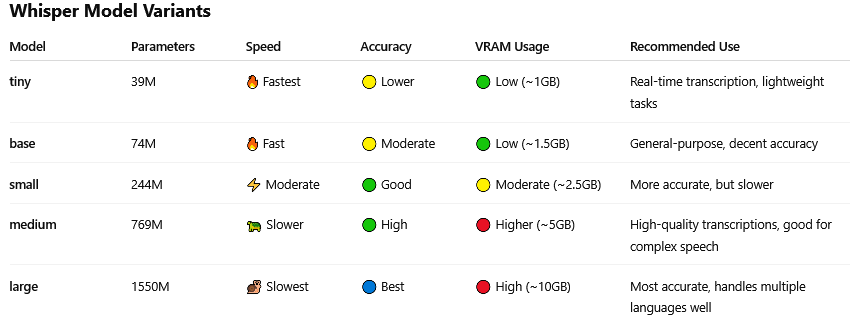

# **Cargar archivos WAV desde Google Drive**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

# Define la ruta de tu carpeta dentro de Google Drive (solo deben haber archivos de sonido)
folder_path = "/content/drive/MyDrive/Colab Notebooks/Data Science WAV Youtube/Audio"

# Obtener todas las rutas de acceso de los archivos
file_paths = [os.path.join(folder_path, file) for file in os.listdir(folder_path)]

# Imprimir rutas de archivo y procesar con funcion de transcripción (se guarda en archivo txt en carpeta especifica)
i=0
for path in file_paths:
    print("Procesando archivo: ", path)
    transcription = transcribe_audio(path, model_type = "small", idioma = "es")
    with open("/content/drive/MyDrive/Colab Notebooks/Data Science WAV Youtube/Transcripcion/Transcripcion.txt", "a") as file:
      file.write(path)
      file.write("\n")
      file.write(transcription)
      file.write("\n")
      file.write("---------------------------------------- \n" )
    print(f"Transcripcion_{i+1} guardada en output_1.txt : \n" , transcription)
    print("---------------------------------------- \n")

Procesando archivo:  /content/drive/MyDrive/Colab Notebooks/Data Science WAV Youtube/Audio/tran.mp4


100%|████████████████████████████████████████| 461M/461M [00:04<00:00, 101MiB/s]


Transcripcion_1 guardada en output_1.txt : 
  ¿Está el vampiro? ¿Ya? ¿Estabiste? No, no sé, el vampiro lo está... Bueno, la entrevista con el vampiro es una película que es una obra de arte, güey. ¿Ya? Es... bueno... Hay un vampiro que tiene muchos cientos de años, que está en esta época, y va al psicólogo. ¿Ya? Y el huevón tiene una entrevista con el psicólogo, o sea, el vampiro tiene una entrevista con el psicólogo. Y a través de la entrevista, le va contando toda su vida desde que fue vampiro. ¿Ya? Entonces, hay cuestiones como de fondo, súper interesante, güey. Me gusta mucho, es muy linda, güey, muy bonita. Bueno, en esa entrevista con el vampiro sale un vampiro que se llama Armando. ¿Ya? Pero hay un libro que es el libro de Armando. ¿Cachai? Entonces, ese mismo autor tiene varios libros de vampiro, y son súper entretenidos. Todos. Todos. El Leo II. El Leo II. ¿Cuál es? Bueno, en la entrevista con el vampiro, no, Armando el vampiro, y el otro que se llama, que es la que le sigue. 

# **Transcribir video You Tube o desde otro sitio**

In [ ]:
!pip install yt-dlp

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.3/180.3 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 82.0 MB/s eta 0:00:00


In [ ]:
import os
import yt_dlp

#Funcion descarga audio video YT y lo guarda como MP3
def download_mp3(video_url, output_dir="Descarga_audio_YT"): #Video_url es url video YT, output_dir: carpeta temporal par aguardar audio
    os.makedirs(output_dir, exist_ok=True) #crea directorio temporal

    ydl_opts = {
        'format': 'bestaudio/best', #indica que descargue el mejor audio disponible del video.
        'outtmpl': os.path.join(output_dir, '%(title)s.%(ext)s'), #define el nombre del archivo de salida (nombre del video YT).
        'postprocessors': [{        #proceso despues de descarga audio
            'key': 'FFmpegExtractAudio', #extrae audio
            'preferredcodec': 'mp3', #convierte a mp3
            'preferredquality': '192', #calidad audio
        }],
        'quiet': False, #muestra mensajes durante la descarga (útil para depurar)
    }

    with yt_dlp.YoutubeDL(ydl_opts) as ydl:               #Se crea un objeto YoutubeDL (ydl) con las opciones configuradas.
        info = ydl.extract_info(video_url, download=True) #Extrae toda la información del video (como título, duración, etc.) y lo descarga.
        title = info['title']                             #Usa el título del video para construir el nombre del archivo .mp3
        mp3_filename = os.path.join(output_dir, f"{title}.mp3") #Lo combina con la carpeta de salida (output_dir) para obtener la ruta completa.
        return mp3_filename

In [ ]:

if __name__ == "__main__":                    #encapsula el código que quieres que se ejecute solo si corres el archivo directamente

    video_url = "https://www.ted.com/talks/rebeca_hwang_el_valor_de_nuestra_diversidad_interna" # Cambia esta URL por cualquier video de YouTube que desees transcribir

    try:
        mp3_file = download_mp3(video_url)          #Llama a la función download_mp3() que ya analizamos antes
        print(f"\n Audio descargado: {mp3_file}\n") # ver nombre archivo audio
        text = transcribe_audio(mp3_file, model_type="medium", idioma="es") # funcion para transcribir
        print("\n Transcripción:\n")
        print(text)                       #imprime transcripción
    except Exception as e:                #Si ocurre cualquier excepción en el bloque try, se ejecuta este bloque.
        print(f"Error en descarga: {e}")


[TedTalk] Extracting URL: https://www.ted.com/talks/rebeca_hwang_el_valor_de_nuestra_diversidad_interna
[TedTalk] rebeca_hwang_el_valor_de_nuestra_diversidad_interna: Downloading webpage
[TedTalk] 19714: Downloading m3u8 information
[info] 19714: Downloading 1 format(s): hls-audio0-medium
[hlsnative] Downloading m3u8 manifest
[hlsnative] Total fragments: 122
[download] Destination: Descarga_audio_YT/El valor de nuestra diversidad interna.mp4
[download] 100% of   12.19MiB in 00:00:28 at 434.66KiB/s                 
[FixupM3u8] Fixing MPEG-TS in MP4 container of "Descarga_audio_YT/El valor de nuestra diversidad interna.mp4"
[ExtractAudio] Destination: Descarga_audio_YT/El valor de nuestra diversidad interna.mp3
Deleting original file Descarga_audio_YT/El valor de nuestra diversidad interna.mp4 (pass -k to keep)

 Audio descargado: Descarga_audio_YT/El valor de nuestra diversidad interna.mp3



100%|█████████████████████████████████████| 1.42G/1.42G [00:18<00:00, 83.0MiB/s]



 Transcripción:

 Agarrados a las manos, mirábamos la puerta y estábamos perforando la puerta con nuestras miradas intensas. Mis hermanos y yo estábamos esperando a que mi mamá volviera del hospital, donde mi abuela estaba haciendo operada por un cáncer avanzado. Por fin las puertas se abrieron y mi mamá dijo, no sobrevivió la operación. Ella estalló en llantos y entre los oyosos nos dijo, el último deseo de tu abuela fue ser enterrada en su hogar, en Corea. Yo tenía apenas 12 años con este episodio y cuando me recuperé de ese shock inicial, las palabras de mi madre estaban retumbando en mis oídos. La abu quería ser enterrada en su hogar. Nosotros habíamos emigrado de Corea a Argentina hacia seis años ya, cuando no sabíamos nada de español ni sabíamos cómo íbamos a ganar las vidas. Éramos inmigrantes en una nueva tierra en donde lo habíamos perdido todo a través de una estafa y habíamos trabajado muy duro para poder rehacer nuestras vidas. Por eso no me imaginaba que después de tantos

In [ ]:



if __name__ == "__main__":                    #encapsula el código que quieres que se ejecute solo si corres el archivo directamente

    video_url = "https://youtu.be/MAp4m2ETA3A?si=BieGZUWXIISwA26S" # Cambia esta URL por cualquier video de YouTube que desees transcribir

    try:
        mp3_file = download_mp3(video_url)          #Llama a la función download_mp3() que ya analizamos antes
        print(f"\n Audio descargado: {mp3_file}\n") # ver nombre archivo audio
        text = transcribe_audio(mp3_file, model_type="medium", idioma="es") # funcion para transcribir
        print("\n Transcripción:\n")
        print(text)                       #imprime transcripción
    except Exception as e:                #Si ocurre cualquier excepción en el bloque try, se ejecuta este bloque.
        print(f"Error en descarga: {e}")


[youtube] Extracting URL: https://youtu.be/MAp4m2ETA3A?si=BieGZUWXIISwA26S
[youtube] MAp4m2ETA3A: Downloading webpage


[youtube] MAp4m2ETA3A: Downloading android sdkless player API JSON
[youtube] MAp4m2ETA3A: Downloading web safari player API JSON


[youtube] MAp4m2ETA3A: Downloading m3u8 information


[info] MAp4m2ETA3A: Downloading 1 format(s): 251-1
[download] Destination: Descarga_audio_YT/31 Minutos RADICALIZÓ a Toda una GENERACIÓN.webm
[download] 100% of   15.29MiB in 00:00:00 at 23.51MiB/s  
[ExtractAudio] Destination: Descarga_audio_YT/31 Minutos RADICALIZÓ a Toda una GENERACIÓN.mp3


KeyboardInterrupt: 

# **Transcribir audio a texto**

In [ ]:
import os

# Define la ruta de tu carpeta dentro de Google Drive (solo deben haber archivos de sonido)
folder_path = "/content/drive/MyDrive/Colab Notebooks/Data Science WAV Youtube/Nuevo_audio"

# Obtener todas las rutas de acceso de los archivos
file_paths = [os.path.join(folder_path, file) for file in os.listdir(folder_path)]

# Imprimir rutas de archivo y procesar con funcion de transcripción (se guarda en archivo txt en carpeta especifica)
i=0
for path in file_paths:
    print("Procesando archivo: ", path)
    transcription = transcribe_audio(path, model_type = "small", idioma = "en")
    with open("/content/drive/MyDrive/Colab Notebooks/Data Science WAV Youtube/Transcripcion/Transcripcion.txt", "a") as file:
      file.write(path)
      file.write("\n")
      file.write(transcription)
      file.write("\n")
      file.write("---------------------------------------- \n" )
    print(f"Transcripcion_{i+1} guardada en output_1.txt : \n" , transcription)
    print("---------------------------------------- \n")

Procesando archivo:  /content/drive/MyDrive/Colab Notebooks/Data Science WAV Youtube/Nuevo_audio/Audio de WhatsApp 2025-12-08 a las 10.58.05_41fac1a3.dat (online-audio-converter.com).mp3
Transcripcion_1 guardada en output_1.txt : 
  I need to sit down. Only to be quiet. Hello, hello. Hello. Hello. How are you, Angel? Hello. How are you? Hello. Hello. Do you listen to Fidel? Yes, super good. And you? Yes, yes, yes, without any complications. Perfect. Angel, look, this interview has to be done in English. Is that a convenient for you? Non-realian? Yes. Then I need to switch. In English. And so, I'm Angel Oterola. I am the scientist who is leading this project, which I'm looking for a summer student. Thank you for your interest on that particular project. I understand you are applying from the University of Catolica del Maui. Correct. You are connecting from home right now? Yes. Good. So, let me introduce Pamela. Pamela, she's one of my collaborators. She's actually working with data for 